# Techniques for Better Deep Learning Models

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

In [2]:
# Load data into NumPy arrays
data = load_iris()
X, y = data["data"], data["target"]

# convert NumPy array into PyTorch tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

# split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True)

In [3]:
# PyTorch model
class Multiclass(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 8)
        self.act = nn.ReLU()
        self.output = nn.Linear(8, 3)
        self.logsoftmax = nn.LogSoftmax(dim=1)
        
    def forward(self, x):
        x = self.act(self.hidden(x))
        x = self.logsoftmax(self.output(x))
        return x
    
model = Multiclass()

In [4]:
# loss metric and optimizer
loss_fn = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# prepare model and training parameters
n_epochs = 100
batch_size = 5
batch_start = torch.arange(0, len(X), batch_size)

# training loop
for epoch in range(n_epochs):
    for start in batch_start:
        # take a batch
        X_batch = X_train[start:start+batch_size]
        y_batch = y_train[start:start+batch_size]
        # forward pass
        y_pred = model(X_batch)
        loss = loss_fn(y_pred, y_batch)
        # backward pass
        optimizer.zero_grad()
        loss.backward()
        # update weights
        optimizer.step()

In [5]:
...
y_pred = model(X_test)
acc = (torch.argmax(y_pred, 1) == y_test).float().mean()
print("Accuracy: %.2f" % acc)

Accuracy: 0.98


In [6]:
# create a new model
newmodel = Multiclass()
# ask PyTorch to ignore autograd on update and overwrite parameters
with torch.no_grad():
    for newtensor, oldtensor in zip(newmodel.parameters(), model.parameters()):
        newtensor.copy_(oldtensor)
# test with new model using copied tensor
y_pred = newmodel(X_test)
acc = (torch.argmax(y_pred, 1) == y_test).float().mean()
print("Accuracy: %.2f" % acc)

Accuracy: 0.98


In [7]:
import pprint
pp = pprint.PrettyPrinter(indent=4)
pp.pprint(model.state_dict())

OrderedDict([   (   'hidden.weight',
                    tensor([[-0.0990, -0.5774,  0.2309,  0.1942],
        [-0.4478, -0.2174, -0.1833,  0.3820],
        [-0.3167, -0.2770,  0.7891,  0.5371],
        [ 0.2595, -0.3096, -0.1961, -0.0319],
        [-0.2462, -0.3588,  0.1483, -0.2685],
        [-0.1793,  0.3358, -0.3732,  0.3875],
        [ 0.5136,  1.1086, -0.7419, -0.5329],
        [ 0.3571, -0.7639,  0.5856,  0.5944]])),
                (   'hidden.bias',
                    tensor([ 0.2163, -0.0102,  0.0663, -0.3856, -0.1561, -0.0552,  0.2631,  0.0780])),
                (   'output.weight',
                    tensor([[ 9.4840e-02, -4.1985e-02, -1.1347e+00,  1.1249e-01,  1.4215e-01,
         -6.2729e-02,  1.1367e+00, -1.4485e+00],
        [-2.0720e-02,  3.1477e-01, -7.0013e-01, -2.8636e-01,  1.9876e-01,
          2.0303e-01,  3.9278e-01,  2.7785e-01],
        [-2.0549e-01, -9.3421e-02,  9.3033e-01, -2.5696e-01, -1.0524e-03,
         -1.9101e-01, -6.9902e-01,  1.3655e-01]])),
     

In [8]:
import pickle
# Save model
with open("iris-model.pickle", "wb") as fp:
    pickle.dump(model.state_dict(), fp)

# Create new model and load states
newmodel = Multiclass()
with open("iris-model.pickle", "rb") as fp:
    newmodel.load_state_dict(pickle.load(fp))
    
# test with new model using copied tensor
y_pred = newmodel(X_test)
acc = (torch.argmax(y_pred, 1) == y_test).float().mean()
print("Accuracy: %.2f" % acc)

Accuracy: 0.98


In [9]:
# Save model
torch.save(model.state_dict(), "iris-model.pth")
# Create new model and load states
newmodel = Multiclass()
newmodel.load_state_dict(torch.load("iris-model.pth"))
# test with new model using copied tensor
y_pred = newmodel(X_test)
acc = (torch.argmax(y_pred, 1) == y_test).float().mean()
print("Accuracy: %.2f" % acc)

Accuracy: 0.98


# Using Activation Functions in Deep Learning Models

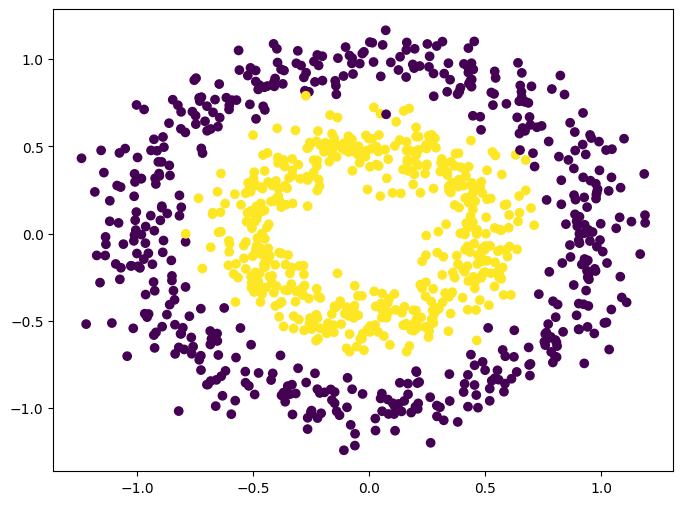

In [12]:
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt
import torch
# Make data: Two circles on x-y plane as a classification problem
X, y = make_circles(n_samples=1000, factor=0.5, noise=0.1)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=y)
plt.show()

In [13]:
class Model(nn.Module):
    def __init__(self, activation=nn.ReLU):
        super().__init__()
        self.layer0 = nn.Linear(2,5)
        self.act0 = activation()
        self.layer1 = nn.Linear(5,5)
        self.act1 = activation()
        self.layer2 = nn.Linear(5,5)
        self.act2 = activation()
        self.layer3 = nn.Linear(5,5)
        self.act3 = activation()
        self.layer4 = nn.Linear(5,1)
        self.act4 = nn.Sigmoid()
    def forward(self, x):
        x = self.act0(self.layer0(x))
        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.act3(self.layer3(x))
        x = self.act4(self.layer4(x))
        return x
    
def train_loop(model, X, y, n_epochs=300, batch_size=32):
    loss_fn = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    batch_start = torch.arange(0, len(X), batch_size)
    bce_hist = []
    acc_hist = []
    for epoch in range(n_epochs):
        # train model with optimizer
        model.train()
        for start in batch_start:
            X_batch = X[start:start+batch_size]
            y_batch = y[start:start+batch_size]
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        # evaluate BCE and accuracy at end of each epoch
        model.eval()
        with torch.no_grad():
            y_pred = model(X)
            bce = float(loss_fn(y_pred, y))
            acc = float((y_pred.round() == y).float().mean())
        bce_hist.append(bce)
        acc_hist.append(acc)
        # print metrics every 10 epochs
        if (epoch+1) % 10 == 0:
            print("Before epoch %d: BCE=%.4f, Accuracy=%.2f%%" % (epoch+1, bce, acc*100))
    return bce_hist, acc_hist

Before epoch 10: BCE=0.6944, Accuracy=50.00%
Before epoch 20: BCE=0.6891, Accuracy=50.00%
Before epoch 30: BCE=0.6846, Accuracy=50.70%
Before epoch 40: BCE=0.6794, Accuracy=78.80%
Before epoch 50: BCE=0.6728, Accuracy=79.60%
Before epoch 60: BCE=0.6624, Accuracy=77.40%
Before epoch 70: BCE=0.6466, Accuracy=77.00%
Before epoch 80: BCE=0.6269, Accuracy=79.40%
Before epoch 90: BCE=0.6042, Accuracy=80.40%
Before epoch 100: BCE=0.5794, Accuracy=80.60%
Before epoch 110: BCE=0.5533, Accuracy=81.30%
Before epoch 120: BCE=0.5260, Accuracy=84.00%
Before epoch 130: BCE=0.4972, Accuracy=86.00%
Before epoch 140: BCE=0.4672, Accuracy=88.30%
Before epoch 150: BCE=0.4365, Accuracy=90.40%
Before epoch 160: BCE=0.4052, Accuracy=92.30%
Before epoch 170: BCE=0.3732, Accuracy=95.60%
Before epoch 180: BCE=0.3417, Accuracy=96.60%
Before epoch 190: BCE=0.3113, Accuracy=97.00%
Before epoch 200: BCE=0.2821, Accuracy=97.00%
Before epoch 210: BCE=0.2548, Accuracy=97.10%
Before epoch 220: BCE=0.2296, Accuracy=97.7

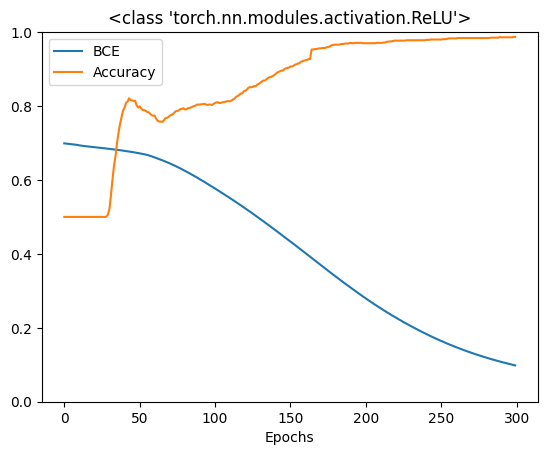

In [14]:
activation = nn.ReLU
model = Model(activation=activation)
bce_hist, acc_hist = train_loop(model, X, y)
plt.plot(bce_hist, label="BCE")
plt.plot(acc_hist, label="Accuracy")
plt.xlabel("Epochs")
plt.ylim(0, 1)
plt.title(str(activation))
plt.legend()
plt.show()

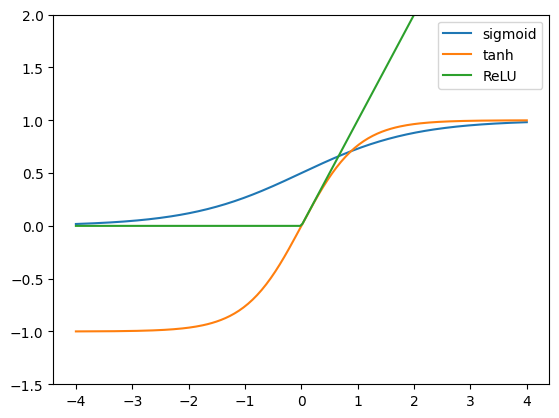

In [15]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
x = torch.linspace(-4, 4, 200)
relu = nn.ReLU()(x)
tanh = nn.Tanh()(x)
sigmoid = nn.Sigmoid()(x)
plt.plot(x, sigmoid, label="sigmoid")
plt.plot(x, tanh, label="tanh")
plt.plot(x, relu, label="ReLU")
plt.ylim(-1.5, 2)
plt.legend()
plt.show()

In [16]:
def train_loop(model, X, y, n_epochs=300, batch_size=32):
    loss_fn = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    batch_start = torch.arange(0, len(X), batch_size)
    bce_hist = []
    acc_hist = []
    grad_hist = [[],[],[],[],[]]
    for epoch in range(n_epochs):
        # train model with optimizer
        model.train()
        layer_grad = [[],[],[],[],[]]
        for start in batch_start:
            X_batch = X[start:start+batch_size]
            y_batch = y[start:start+batch_size]
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            # collect mean absolute value of gradients
            layers = [model.layer0, model.layer1, model.layer2, model.layer3, model.layer4]

            for n,layer in enumerate(layers):
                mean_grad = float(layer.weight.grad.abs().mean())
                layer_grad[n].append(mean_grad)
        # evaluate BCE and accuracy at end of each epoch
        model.eval()
        with torch.no_grad():
            y_pred = model(X)
            bce = float(loss_fn(y_pred, y))
            acc = float((y_pred.round() == y).float().mean())
        bce_hist.append(bce)
        acc_hist.append(acc)
        for n, grads in enumerate(layer_grad):
            grad_hist[n].append(sum(grads)/len(grads))
        # print metrics every 10 epochs
        if epoch % 10 == 9:
            print("Epoch %d: BCE=%.4f, Accuracy=%.2f%%" % (epoch, bce, acc*100))
    return bce_hist, acc_hist, layer_grad

Epoch 9: BCE=0.7045, Accuracy=50.00%
Epoch 19: BCE=0.7010, Accuracy=50.00%
Epoch 29: BCE=0.6973, Accuracy=50.00%
Epoch 39: BCE=0.6932, Accuracy=50.00%
Epoch 49: BCE=0.6885, Accuracy=50.00%
Epoch 59: BCE=0.6832, Accuracy=62.50%
Epoch 69: BCE=0.6771, Accuracy=66.50%
Epoch 79: BCE=0.6702, Accuracy=66.90%
Epoch 89: BCE=0.6623, Accuracy=67.40%
Epoch 99: BCE=0.6518, Accuracy=65.90%
Epoch 109: BCE=0.6366, Accuracy=65.60%
Epoch 119: BCE=0.6217, Accuracy=66.50%
Epoch 129: BCE=0.6068, Accuracy=68.70%
Epoch 139: BCE=0.5918, Accuracy=70.60%
Epoch 149: BCE=0.5767, Accuracy=72.40%
Epoch 159: BCE=0.5620, Accuracy=73.40%
Epoch 169: BCE=0.5475, Accuracy=74.90%
Epoch 179: BCE=0.5333, Accuracy=75.90%
Epoch 189: BCE=0.5201, Accuracy=76.80%
Epoch 199: BCE=0.5081, Accuracy=78.20%
Epoch 209: BCE=0.4970, Accuracy=78.70%
Epoch 219: BCE=0.4867, Accuracy=79.40%
Epoch 229: BCE=0.4769, Accuracy=80.10%
Epoch 239: BCE=0.4677, Accuracy=80.80%
Epoch 249: BCE=0.4588, Accuracy=81.60%
Epoch 259: BCE=0.4504, Accuracy=82.3

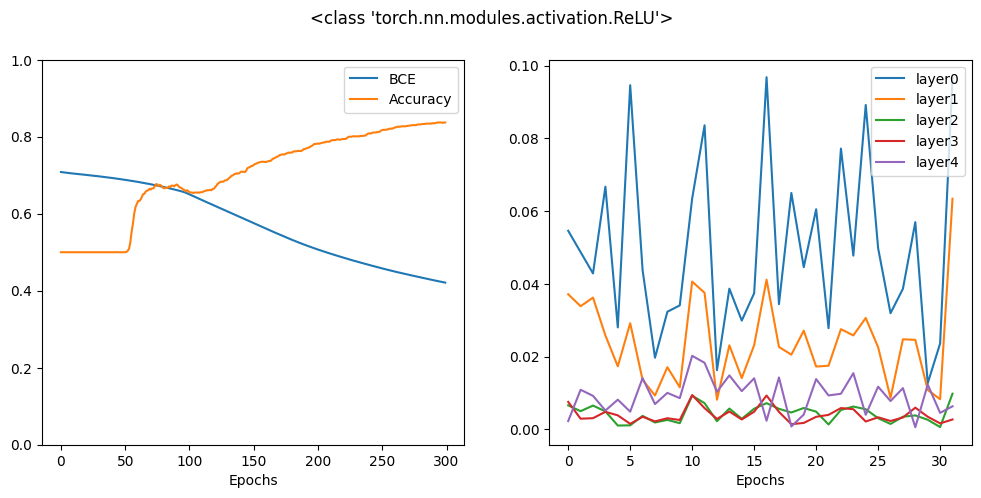

In [17]:
activation = nn.ReLU
model = Model(activation=activation)
bce_hist, acc_hist, grad_hist = train_loop(model, X, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(bce_hist, label="BCE")
ax[0].plot(acc_hist, label="Accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylim(0, 1)
for n, grads in enumerate(grad_hist):
    ax[1].plot(grads, label="layer"+str(n))
ax[1].set_xlabel("Epochs")
fig.suptitle(str(activation))
ax[0].legend()
ax[1].legend()
plt.show()

Epoch 9: BCE=0.7022, Accuracy=50.00%
Epoch 19: BCE=0.6975, Accuracy=50.00%
Epoch 29: BCE=0.6951, Accuracy=50.00%
Epoch 39: BCE=0.6940, Accuracy=50.00%
Epoch 49: BCE=0.6935, Accuracy=50.00%
Epoch 59: BCE=0.6932, Accuracy=50.00%
Epoch 69: BCE=0.6932, Accuracy=50.00%
Epoch 79: BCE=0.6932, Accuracy=50.00%
Epoch 89: BCE=0.6931, Accuracy=50.00%
Epoch 99: BCE=0.6932, Accuracy=50.00%
Epoch 109: BCE=0.6932, Accuracy=50.00%
Epoch 119: BCE=0.6932, Accuracy=50.00%
Epoch 129: BCE=0.6932, Accuracy=50.00%
Epoch 139: BCE=0.6932, Accuracy=50.00%
Epoch 149: BCE=0.6932, Accuracy=50.00%
Epoch 159: BCE=0.6932, Accuracy=50.00%
Epoch 169: BCE=0.6932, Accuracy=50.00%
Epoch 179: BCE=0.6932, Accuracy=50.00%
Epoch 189: BCE=0.6932, Accuracy=50.00%
Epoch 199: BCE=0.6932, Accuracy=50.00%
Epoch 209: BCE=0.6932, Accuracy=50.00%
Epoch 219: BCE=0.6932, Accuracy=50.00%
Epoch 229: BCE=0.6932, Accuracy=50.00%
Epoch 239: BCE=0.6932, Accuracy=50.00%
Epoch 249: BCE=0.6932, Accuracy=50.00%
Epoch 259: BCE=0.6932, Accuracy=50.0

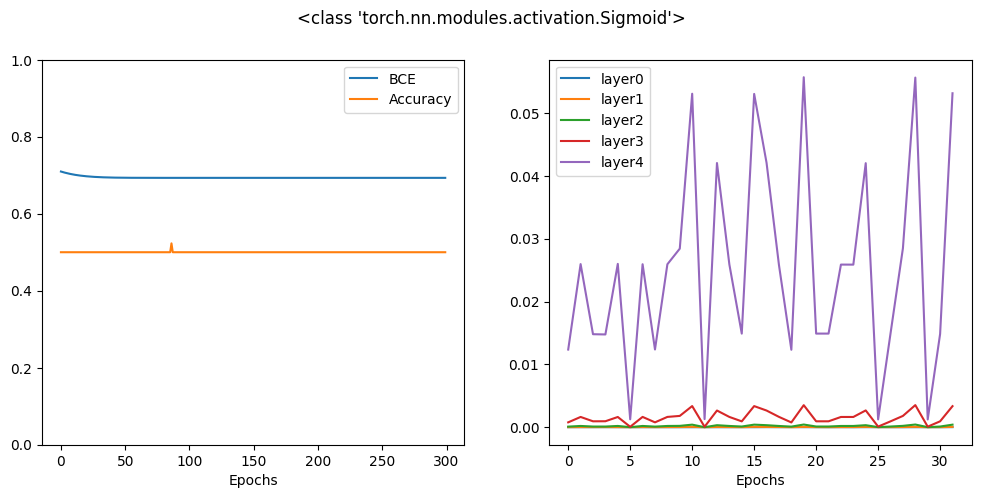

In [18]:
activation = nn.Sigmoid
model = Model(activation=activation)
bce_hist, acc_hist, grad_hist = train_loop(model, X, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(bce_hist, label="BCE")
ax[0].plot(acc_hist, label="Accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylim(0, 1)
for n, grads in enumerate(grad_hist):
    ax[1].plot(grads, label="layer"+str(n))
ax[1].set_xlabel("Epochs")
fig.suptitle(str(activation))
ax[0].legend()
ax[1].legend()
plt.show()

Epoch 9: BCE=0.6939, Accuracy=50.00%
Epoch 19: BCE=0.6932, Accuracy=50.00%
Epoch 29: BCE=0.6928, Accuracy=46.60%
Epoch 39: BCE=0.6925, Accuracy=49.70%
Epoch 49: BCE=0.6921, Accuracy=55.20%
Epoch 59: BCE=0.6914, Accuracy=57.80%
Epoch 69: BCE=0.6904, Accuracy=60.80%
Epoch 79: BCE=0.6888, Accuracy=61.90%
Epoch 89: BCE=0.6863, Accuracy=61.50%
Epoch 99: BCE=0.6829, Accuracy=61.50%
Epoch 109: BCE=0.6785, Accuracy=61.70%
Epoch 119: BCE=0.6733, Accuracy=62.40%
Epoch 129: BCE=0.6676, Accuracy=63.20%
Epoch 139: BCE=0.6615, Accuracy=63.50%
Epoch 149: BCE=0.6553, Accuracy=63.40%
Epoch 159: BCE=0.6490, Accuracy=63.90%
Epoch 169: BCE=0.6425, Accuracy=64.20%
Epoch 179: BCE=0.6356, Accuracy=64.30%
Epoch 189: BCE=0.6284, Accuracy=64.60%
Epoch 199: BCE=0.6207, Accuracy=65.10%
Epoch 209: BCE=0.6126, Accuracy=65.60%
Epoch 219: BCE=0.6039, Accuracy=69.00%
Epoch 229: BCE=0.5948, Accuracy=74.60%
Epoch 239: BCE=0.5853, Accuracy=77.10%
Epoch 249: BCE=0.5754, Accuracy=77.50%
Epoch 259: BCE=0.5651, Accuracy=78.1

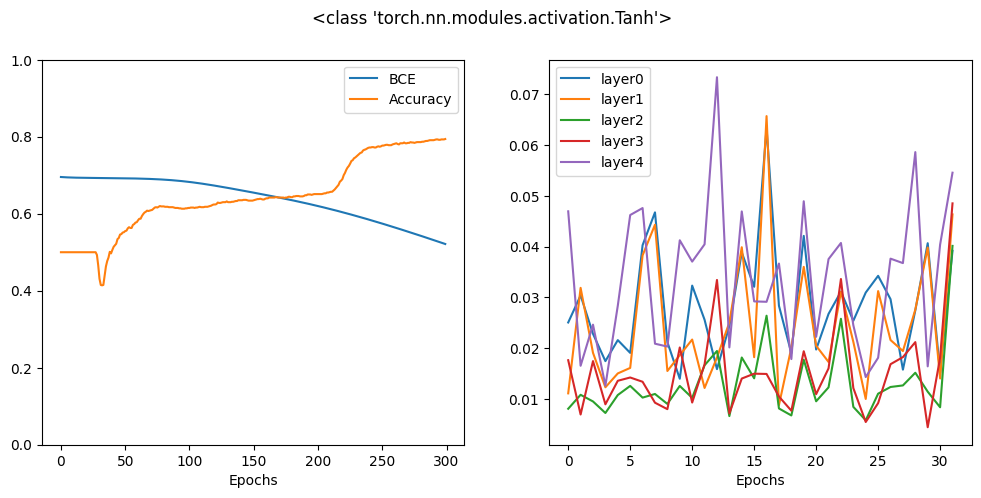

In [19]:
activation = nn.Tanh
model = Model(activation=activation)
bce_hist, acc_hist, grad_hist = train_loop(model, X, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(bce_hist, label="BCE")
ax[0].plot(acc_hist, label="Accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylim(0, 1)
for n, grads in enumerate(grad_hist):
    ax[1].plot(grads, label="layer"+str(n))
ax[1].set_xlabel("Epochs")
fig.suptitle(str(activation))
ax[0].legend()
ax[1].legend()
plt.show()

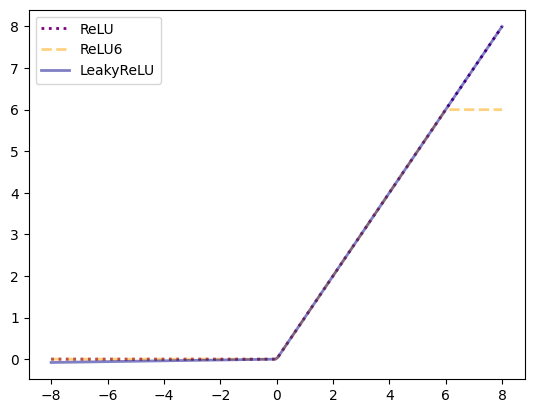

In [20]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
x = torch.linspace(-8,8,200)
relu = nn.ReLU()(x)
relu6 = nn.ReLU6()(x)
leaky = nn.LeakyReLU()(x)
plt.plot(x, relu, c="purple", lw=2, ls=":", label="ReLU")
plt.plot(x, relu6, c="orange", lw=2, ls="--", alpha=0.5, label="ReLU6")
plt.plot(x, leaky, c="darkblue", lw=2, alpha=0.5, label="LeakyReLU")
plt.legend()
plt.show()

Epoch 9: BCE=0.6997, Accuracy=50.00%
Epoch 19: BCE=0.6955, Accuracy=50.00%
Epoch 29: BCE=0.6927, Accuracy=50.00%
Epoch 39: BCE=0.6911, Accuracy=52.60%
Epoch 49: BCE=0.6901, Accuracy=59.50%
Epoch 59: BCE=0.6891, Accuracy=55.00%
Epoch 69: BCE=0.6879, Accuracy=53.30%
Epoch 79: BCE=0.6866, Accuracy=53.30%
Epoch 89: BCE=0.6848, Accuracy=54.30%
Epoch 99: BCE=0.6826, Accuracy=55.70%
Epoch 109: BCE=0.6799, Accuracy=57.00%
Epoch 119: BCE=0.6765, Accuracy=57.40%
Epoch 129: BCE=0.6723, Accuracy=58.20%
Epoch 139: BCE=0.6669, Accuracy=59.30%
Epoch 149: BCE=0.6602, Accuracy=60.80%
Epoch 159: BCE=0.6516, Accuracy=62.60%
Epoch 169: BCE=0.6408, Accuracy=63.90%
Epoch 179: BCE=0.6277, Accuracy=65.70%
Epoch 189: BCE=0.6117, Accuracy=67.40%
Epoch 199: BCE=0.5919, Accuracy=70.10%
Epoch 209: BCE=0.5675, Accuracy=74.50%
Epoch 219: BCE=0.5382, Accuracy=81.10%
Epoch 229: BCE=0.5048, Accuracy=85.50%
Epoch 239: BCE=0.4643, Accuracy=90.40%
Epoch 249: BCE=0.4261, Accuracy=92.00%
Epoch 259: BCE=0.3894, Accuracy=93.3

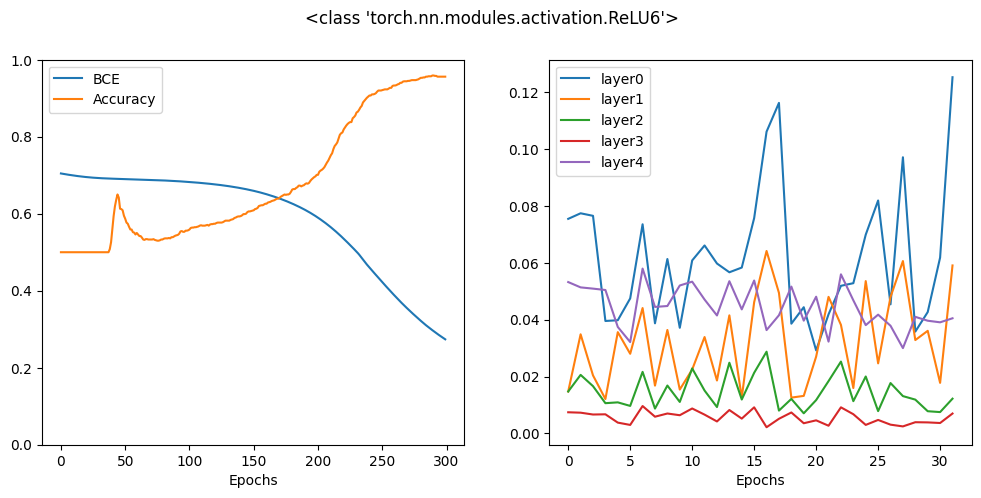

In [21]:
activation = nn.ReLU6
model = Model(activation=activation)
bce_hist, acc_hist, grad_hist = train_loop(model, X, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(bce_hist, label="BCE")
ax[0].plot(acc_hist, label="Accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylim(0, 1)
for n, grads in enumerate(grad_hist):
    ax[1].plot(grads, label="layer"+str(n))
ax[1].set_xlabel("Epochs")
fig.suptitle(str(activation))
ax[0].legend()
ax[1].legend()
plt.show()

Epoch 9: BCE=0.7165, Accuracy=50.00%
Epoch 19: BCE=0.7120, Accuracy=50.00%
Epoch 29: BCE=0.7091, Accuracy=50.00%
Epoch 39: BCE=0.7070, Accuracy=50.00%
Epoch 49: BCE=0.7051, Accuracy=50.00%
Epoch 59: BCE=0.7033, Accuracy=50.00%
Epoch 69: BCE=0.7017, Accuracy=50.00%
Epoch 79: BCE=0.7001, Accuracy=50.00%
Epoch 89: BCE=0.6984, Accuracy=50.00%
Epoch 99: BCE=0.6959, Accuracy=50.00%
Epoch 109: BCE=0.6929, Accuracy=50.00%
Epoch 119: BCE=0.6887, Accuracy=50.00%
Epoch 129: BCE=0.6826, Accuracy=50.00%
Epoch 139: BCE=0.6748, Accuracy=50.00%
Epoch 149: BCE=0.6593, Accuracy=50.00%
Epoch 159: BCE=0.6478, Accuracy=50.00%
Epoch 169: BCE=0.6368, Accuracy=50.00%
Epoch 179: BCE=0.6246, Accuracy=50.00%
Epoch 189: BCE=0.6087, Accuracy=68.00%
Epoch 199: BCE=0.5895, Accuracy=72.50%
Epoch 209: BCE=0.5668, Accuracy=75.30%
Epoch 219: BCE=0.5444, Accuracy=77.40%
Epoch 229: BCE=0.5241, Accuracy=78.90%
Epoch 239: BCE=0.5052, Accuracy=80.20%
Epoch 249: BCE=0.4871, Accuracy=81.10%
Epoch 259: BCE=0.4685, Accuracy=81.2

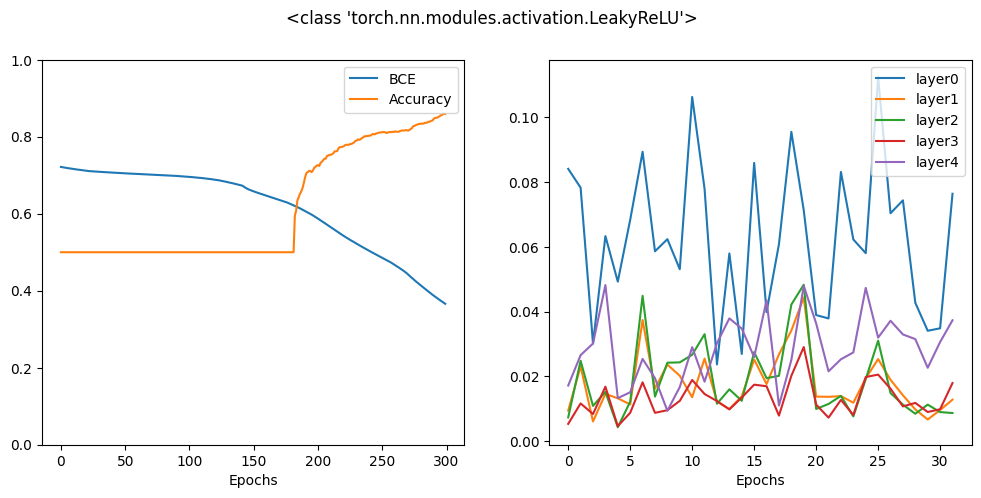

In [22]:
activation = nn.LeakyReLU
model = Model(activation=activation)
bce_hist, acc_hist, grad_hist = train_loop(model, X, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(bce_hist, label="BCE")
ax[0].plot(acc_hist, label="Accuracy")
ax[0].set_xlabel("Epochs")
ax[0].set_ylim(0, 1)
for n, grads in enumerate(grad_hist):
    ax[1].plot(grads, label="layer"+str(n))
ax[1].set_xlabel("Epochs")
fig.suptitle(str(activation))
ax[0].legend()
ax[1].legend()
plt.show()

Epoch 9: BCE=0.6949, Accuracy=50.00%
Epoch 19: BCE=0.6939, Accuracy=50.00%
Epoch 29: BCE=0.6934, Accuracy=50.00%
Epoch 39: BCE=0.6932, Accuracy=50.00%
Epoch 49: BCE=0.6932, Accuracy=50.00%
Epoch 59: BCE=0.6932, Accuracy=50.00%
Epoch 69: BCE=0.6932, Accuracy=50.00%
Epoch 79: BCE=0.6932, Accuracy=50.00%
Epoch 89: BCE=0.6932, Accuracy=50.00%
Epoch 99: BCE=0.6932, Accuracy=50.00%
Epoch 109: BCE=0.6933, Accuracy=50.00%
Epoch 119: BCE=0.6933, Accuracy=50.00%
Epoch 129: BCE=0.6933, Accuracy=50.00%
Epoch 139: BCE=0.6933, Accuracy=50.00%
Epoch 149: BCE=0.6933, Accuracy=50.00%
Epoch 159: BCE=0.6933, Accuracy=50.00%
Epoch 169: BCE=0.6933, Accuracy=50.00%
Epoch 179: BCE=0.6933, Accuracy=50.00%
Epoch 189: BCE=0.6933, Accuracy=50.00%
Epoch 199: BCE=0.6933, Accuracy=50.00%
Epoch 209: BCE=0.6933, Accuracy=50.00%
Epoch 219: BCE=0.6933, Accuracy=50.00%
Epoch 229: BCE=0.6933, Accuracy=50.00%
Epoch 239: BCE=0.6933, Accuracy=50.00%
Epoch 249: BCE=0.6933, Accuracy=50.00%
Epoch 259: BCE=0.6933, Accuracy=50.0

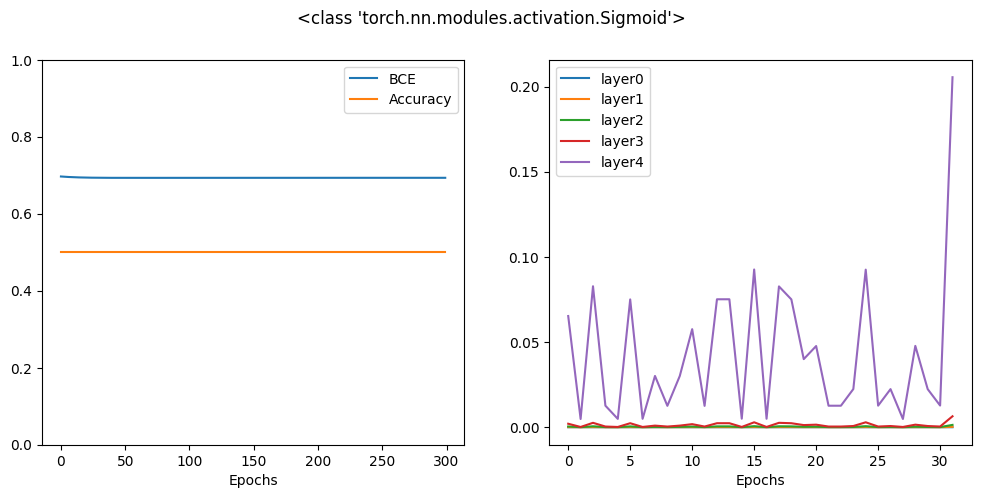

Epoch 9: BCE=0.6945, Accuracy=50.00%
Epoch 19: BCE=0.6937, Accuracy=50.00%
Epoch 29: BCE=0.6933, Accuracy=50.00%
Epoch 39: BCE=0.6929, Accuracy=50.00%
Epoch 49: BCE=0.6926, Accuracy=50.00%
Epoch 59: BCE=0.6923, Accuracy=50.00%
Epoch 69: BCE=0.6920, Accuracy=50.00%
Epoch 79: BCE=0.6915, Accuracy=40.30%
Epoch 89: BCE=0.6909, Accuracy=47.60%
Epoch 99: BCE=0.6901, Accuracy=50.30%
Epoch 109: BCE=0.6890, Accuracy=51.90%
Epoch 119: BCE=0.6873, Accuracy=54.50%
Epoch 129: BCE=0.6849, Accuracy=56.80%
Epoch 139: BCE=0.6814, Accuracy=59.00%
Epoch 149: BCE=0.6762, Accuracy=61.90%
Epoch 159: BCE=0.6688, Accuracy=64.30%
Epoch 169: BCE=0.6583, Accuracy=67.80%
Epoch 179: BCE=0.6439, Accuracy=70.10%
Epoch 189: BCE=0.6244, Accuracy=73.20%
Epoch 199: BCE=0.5992, Accuracy=83.70%
Epoch 209: BCE=0.5682, Accuracy=93.60%
Epoch 219: BCE=0.5318, Accuracy=96.00%
Epoch 229: BCE=0.4903, Accuracy=98.20%
Epoch 239: BCE=0.4450, Accuracy=98.80%
Epoch 249: BCE=0.3978, Accuracy=99.10%
Epoch 259: BCE=0.3510, Accuracy=99.2

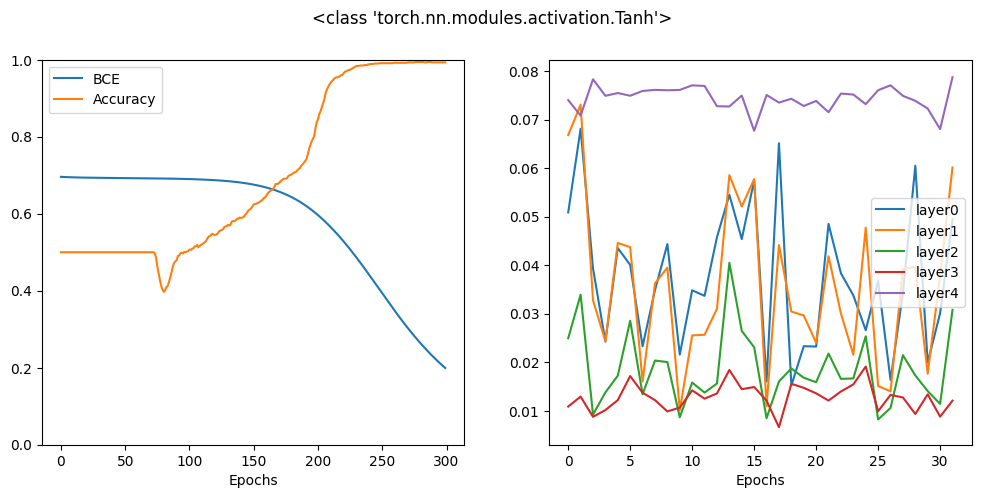

Epoch 9: BCE=0.6952, Accuracy=50.00%
Epoch 19: BCE=0.6945, Accuracy=50.00%
Epoch 29: BCE=0.6939, Accuracy=50.00%
Epoch 39: BCE=0.6931, Accuracy=50.00%
Epoch 49: BCE=0.6921, Accuracy=50.00%
Epoch 59: BCE=0.6909, Accuracy=50.00%
Epoch 69: BCE=0.6893, Accuracy=50.00%
Epoch 79: BCE=0.6873, Accuracy=50.00%
Epoch 89: BCE=0.6848, Accuracy=61.50%
Epoch 99: BCE=0.6816, Accuracy=71.00%
Epoch 109: BCE=0.6777, Accuracy=76.40%
Epoch 119: BCE=0.6730, Accuracy=76.70%
Epoch 129: BCE=0.6666, Accuracy=76.90%
Epoch 139: BCE=0.6497, Accuracy=76.30%
Epoch 149: BCE=0.6372, Accuracy=76.10%
Epoch 159: BCE=0.6252, Accuracy=77.30%
Epoch 169: BCE=0.6137, Accuracy=77.40%
Epoch 179: BCE=0.6027, Accuracy=77.50%
Epoch 189: BCE=0.5923, Accuracy=77.70%
Epoch 199: BCE=0.5824, Accuracy=77.70%
Epoch 209: BCE=0.5731, Accuracy=77.50%
Epoch 219: BCE=0.5645, Accuracy=77.30%
Epoch 229: BCE=0.5566, Accuracy=77.30%
Epoch 239: BCE=0.5492, Accuracy=77.50%
Epoch 249: BCE=0.5424, Accuracy=77.30%
Epoch 259: BCE=0.5360, Accuracy=77.3

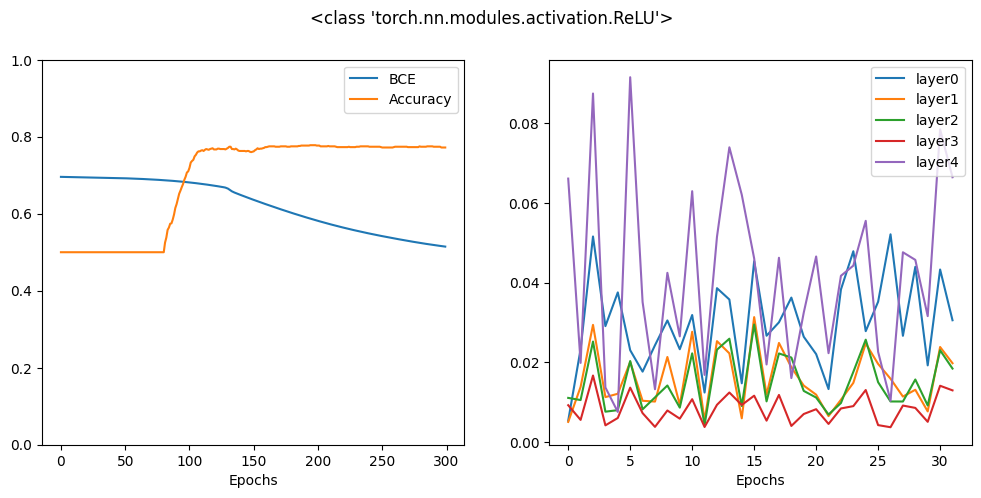

Epoch 9: BCE=0.6933, Accuracy=50.00%
Epoch 19: BCE=0.6926, Accuracy=50.00%
Epoch 29: BCE=0.6917, Accuracy=50.00%
Epoch 39: BCE=0.6905, Accuracy=64.70%
Epoch 49: BCE=0.6887, Accuracy=66.60%
Epoch 59: BCE=0.6857, Accuracy=78.20%
Epoch 69: BCE=0.6815, Accuracy=82.10%
Epoch 79: BCE=0.6759, Accuracy=83.00%
Epoch 89: BCE=0.6679, Accuracy=85.70%
Epoch 99: BCE=0.6542, Accuracy=89.70%
Epoch 109: BCE=0.6370, Accuracy=91.60%
Epoch 119: BCE=0.6177, Accuracy=92.30%
Epoch 129: BCE=0.5959, Accuracy=92.80%
Epoch 139: BCE=0.5720, Accuracy=93.80%
Epoch 149: BCE=0.5462, Accuracy=95.10%
Epoch 159: BCE=0.5180, Accuracy=95.80%
Epoch 169: BCE=0.4885, Accuracy=96.90%
Epoch 179: BCE=0.4573, Accuracy=97.40%
Epoch 189: BCE=0.4256, Accuracy=97.50%
Epoch 199: BCE=0.3945, Accuracy=97.80%
Epoch 209: BCE=0.3644, Accuracy=98.10%
Epoch 219: BCE=0.3358, Accuracy=98.30%
Epoch 229: BCE=0.3086, Accuracy=98.30%
Epoch 239: BCE=0.2832, Accuracy=98.10%
Epoch 249: BCE=0.2598, Accuracy=98.30%
Epoch 259: BCE=0.2382, Accuracy=98.2

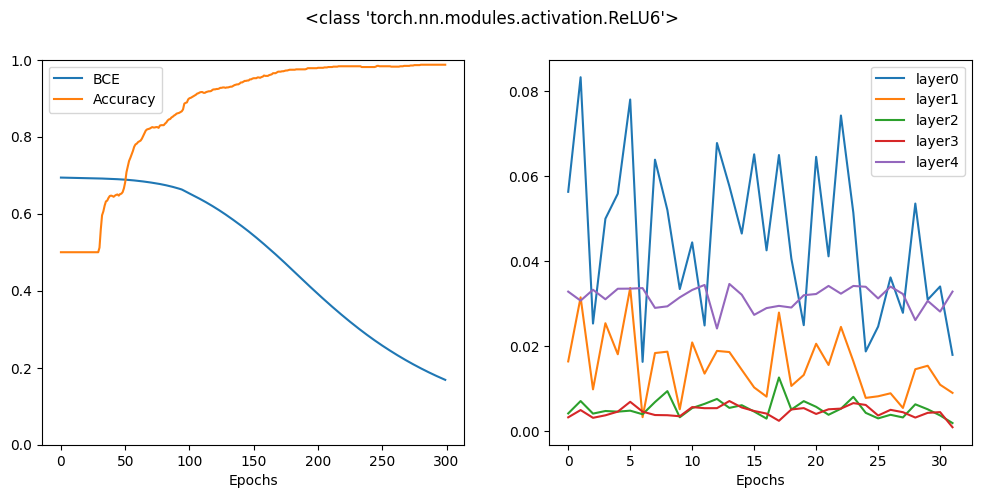

Epoch 9: BCE=0.7031, Accuracy=50.00%
Epoch 19: BCE=0.6998, Accuracy=50.00%
Epoch 29: BCE=0.6968, Accuracy=50.00%
Epoch 39: BCE=0.6944, Accuracy=50.00%
Epoch 49: BCE=0.6923, Accuracy=50.00%
Epoch 59: BCE=0.6906, Accuracy=50.00%
Epoch 69: BCE=0.6889, Accuracy=52.50%
Epoch 79: BCE=0.6839, Accuracy=60.80%
Epoch 89: BCE=0.6802, Accuracy=63.50%
Epoch 99: BCE=0.6762, Accuracy=65.00%
Epoch 109: BCE=0.6717, Accuracy=64.30%
Epoch 119: BCE=0.6667, Accuracy=63.60%
Epoch 129: BCE=0.6612, Accuracy=63.70%
Epoch 139: BCE=0.6550, Accuracy=65.50%
Epoch 149: BCE=0.6459, Accuracy=67.20%
Epoch 159: BCE=0.6354, Accuracy=68.80%
Epoch 169: BCE=0.6242, Accuracy=69.60%
Epoch 179: BCE=0.6125, Accuracy=71.80%
Epoch 189: BCE=0.6000, Accuracy=73.40%
Epoch 199: BCE=0.5830, Accuracy=75.00%
Epoch 209: BCE=0.5611, Accuracy=76.90%
Epoch 219: BCE=0.5403, Accuracy=78.30%
Epoch 229: BCE=0.5202, Accuracy=80.40%
Epoch 239: BCE=0.5006, Accuracy=81.80%
Epoch 249: BCE=0.4818, Accuracy=82.80%
Epoch 259: BCE=0.4638, Accuracy=83.3

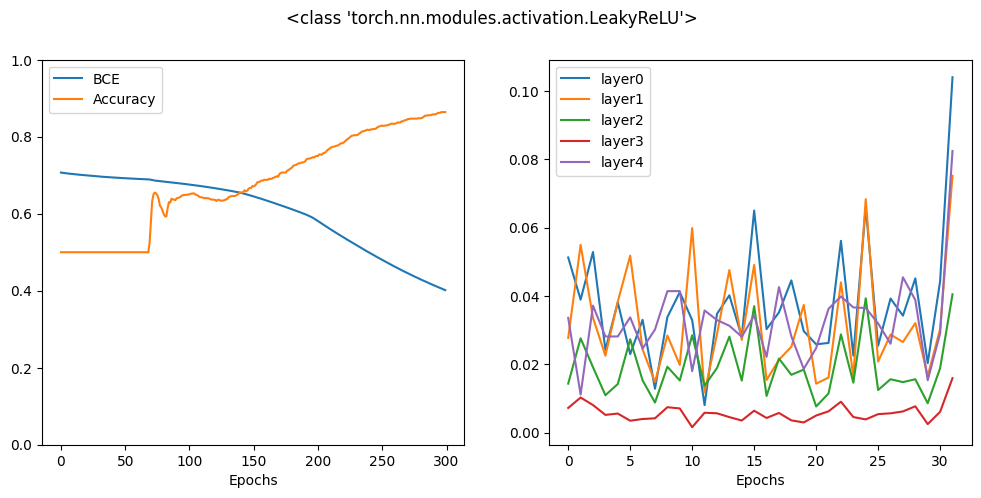

In [23]:
from sklearn.datasets import make_circles
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
# Make data: Two circles on x-y plane as a classification problem
X, y = make_circles(n_samples=1000, factor=0.5, noise=0.1)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)
# Binary classification model
class Model(nn.Module):
    def __init__(self, activation=nn.ReLU):
        super().__init__()
        self.layer0 = nn.Linear(2,5)
        self.act0 = activation()
        self.layer1 = nn.Linear(5,5)
        self.act1 = activation()
        self.layer2 = nn.Linear(5,5)
        self.act2 = activation()
        self.layer3 = nn.Linear(5,5)
        self.act3 = activation()
        self.layer4 = nn.Linear(5,1)
        self.act4 = nn.Sigmoid()
    def forward(self, x):
        x = self.act0(self.layer0(x))
        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.act3(self.layer3(x))
        x = self.act4(self.layer4(x))
        return x
# train the model and produce history
def train_loop(model, X, y, n_epochs=300, batch_size=32):
    loss_fn = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    batch_start = torch.arange(0, len(X), batch_size)
    bce_hist = []
    acc_hist = []
    grad_hist = [[],[],[],[],[]]
    for epoch in range(n_epochs):
        # train model with optimizer
        model.train()
        layer_grad = [[],[],[],[],[]]
        for start in batch_start:
            X_batch = X[start:start+batch_size]
            y_batch = y[start:start+batch_size]
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            # collect mean absolute value of gradients
            layers = [model.layer0, model.layer1, model.layer2, model.layer3, model.layer4]

            for n,layer in enumerate(layers):
                mean_grad = float(layer.weight.grad.abs().mean())
                layer_grad[n].append(mean_grad)
        # evaluate BCE and accuracy at end of each epoch
        model.eval()
        with torch.no_grad():
            y_pred = model(X)
            bce = float(loss_fn(y_pred, y))
            acc = float((y_pred.round() == y).float().mean())
        bce_hist.append(bce)
        acc_hist.append(acc)
        for n, grads in enumerate(layer_grad):
            grad_hist[n].append(sum(grads)/len(grads))
        # print metrics every 10 epochs
        if epoch % 10 == 9:
            print("Epoch %d: BCE=%.4f, Accuracy=%.2f%%" % (epoch, bce, acc*100))
    return bce_hist, acc_hist, layer_grad

# pick different activation functions and compare the result visually
for activation in [nn.Sigmoid, nn.Tanh, nn.ReLU, nn.ReLU6, nn.LeakyReLU]:
    model = Model(activation=activation)
    bce_hist, acc_hist, grad_hist = train_loop(model, X, y)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].plot(bce_hist, label="BCE")
    ax[0].plot(acc_hist, label="Accuracy")
    ax[0].set_xlabel("Epochs")
    ax[0].set_ylim(0, 1)
    for n, grads in enumerate(grad_hist):
        ax[1].plot(grads, label="layer"+str(n))
    ax[1].set_xlabel("Epochs")
    fig.suptitle(str(activation))
    ax[0].legend()
    ax[1].legend()
    plt.show()